In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# hours studied vs pass/fail
x = [0,2,12,0.5,1,19,9,3,5,8,9,2.5,0.3,4.3]
y = [0,0,1,0,0,1,1,0,1,1,1,0,0,1]

14 14


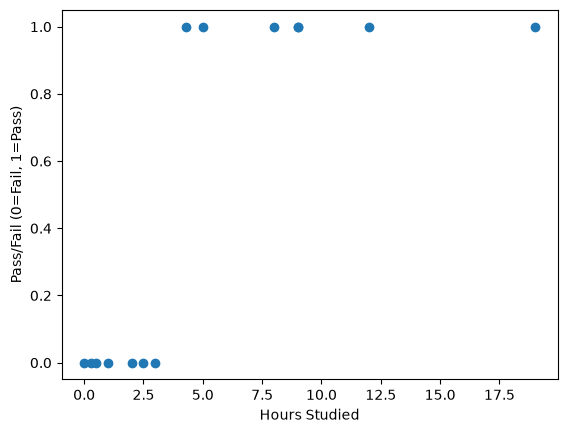

In [3]:
plt.scatter(x, y)
plt.xlabel('Hours Studied')
plt.ylabel('Pass/Fail (0=Fail, 1=Pass)')
plt.show()

In [4]:
import math
def sigmoid(z):
    return 1 / (1 + math.exp(-z))

In [6]:
predictions = []
w = 1
b = -5
for i in range(len(x)):
    z = w * x[i] + b
    pred = sigmoid(z)
    predictions.append(pred)

In [7]:
for i in range(len(x)):
    if(predictions[i] >= 0.5):
        predictions[i] = 1
    else:
        predictions[i] = 0
    print(f"Hours Studied: {x[i]}, Actual: {y[i]}, Predicted: {predictions[i]:.4f}")


Hours Studied: 0, Actual: 0, Predicted: 0.0000
Hours Studied: 2, Actual: 0, Predicted: 0.0000
Hours Studied: 12, Actual: 1, Predicted: 1.0000
Hours Studied: 0.5, Actual: 0, Predicted: 0.0000
Hours Studied: 1, Actual: 0, Predicted: 0.0000
Hours Studied: 19, Actual: 1, Predicted: 1.0000
Hours Studied: 9, Actual: 1, Predicted: 1.0000
Hours Studied: 3, Actual: 0, Predicted: 0.0000
Hours Studied: 5, Actual: 1, Predicted: 1.0000
Hours Studied: 8, Actual: 1, Predicted: 1.0000
Hours Studied: 9, Actual: 1, Predicted: 1.0000
Hours Studied: 2.5, Actual: 0, Predicted: 0.0000
Hours Studied: 0.3, Actual: 0, Predicted: 0.0000
Hours Studied: 4.3, Actual: 1, Predicted: 0.0000


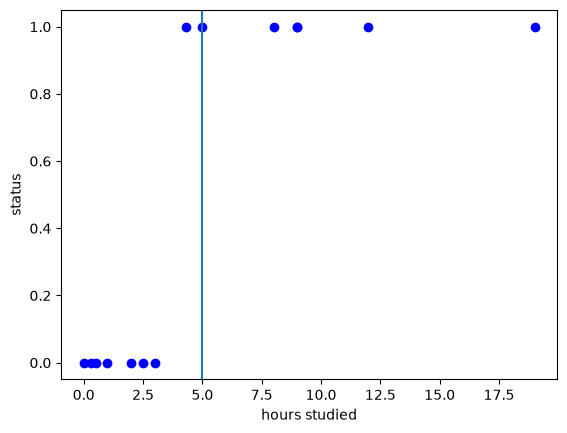

In [10]:
plt.scatter(x, y, label='Actual', color='blue')
x_bound = -b / w
plt.axvline(x_bound)
plt.xlabel("hours studied")
plt.ylabel("status")
plt.show()

In [ ]:
#Cost function
def cost_function(x,y,w,b):
    m = len(x)
    cost = 0
    for i in range(m):
        z = w * x[i] + b
        p = sigmoid(z)
        p = max(1e-15, min(p, 1 - 1e-15))
        cost += -y[i] * math.log(p) - (1 - y[i]) * math.log(1-p)
    return cost / m

In [ ]:
# Brute force search for best w and b
best_w = None
best_b = None
best_cost = float('inf')
for w in np.arange(-5,5.01,0.01):
    for b in np.arange(-100,100,1):
        cost = cost_function(x,y,w,b)
        if(cost < best_cost):
            best_cost = cost
            best_w = w
            best_b = b

print(f"Best w: {best_w}, Best b: {best_b}, Best cost: {best_cost:.4f}")

Best w: 4.979999999999787, Best b: -18, Best cost: 0.0060


In [14]:
#Gradient Descent
def gradient_descent(x,y,w,b,alpha,epochs):
    m = len(x)
    for _ in range(epochs):
        dw_dj = 0
        db_dj = 0
        for i in range(m):
            z = w * x[i] + b
            p = sigmoid(z)
            dw_dj += (p - y[i]) * x[i]
            db_dj += (p - y[i])
        dw_dj /= m
        db_dj /= m
        w -= alpha * dw_dj
        b -= alpha * db_dj

    return w,b


In [17]:
w = 0
b = 0
alpha = 0.01

w,b = gradient_descent(x,y,w,b,alpha,10000)
print(f"Best_w {w}")
print(f"Best_b {b}")
print(f"Best_cost {cost_function(x,y,w,b)}")

Best_w 1.3944733426973102
Best_b -4.956165816570926
Best_cost 0.08466946037166936


In [19]:
predictions = []
for i in range(len(x)):
    z = w * x[i] + b
    pred = sigmoid(z)
    predictions.append(pred)

for x in predictions:
    if(x >= 0.5):
        x = 1
    else:
        x = 0
    print(f"Predicted: {x:.4f}")

Predicted: 0.0000
Predicted: 0.0000
Predicted: 1.0000
Predicted: 0.0000
Predicted: 0.0000
Predicted: 1.0000
Predicted: 1.0000
Predicted: 0.0000
Predicted: 1.0000
Predicted: 1.0000
Predicted: 1.0000
Predicted: 0.0000
Predicted: 0.0000
Predicted: 1.0000


Text(0, 0.5, 'status')

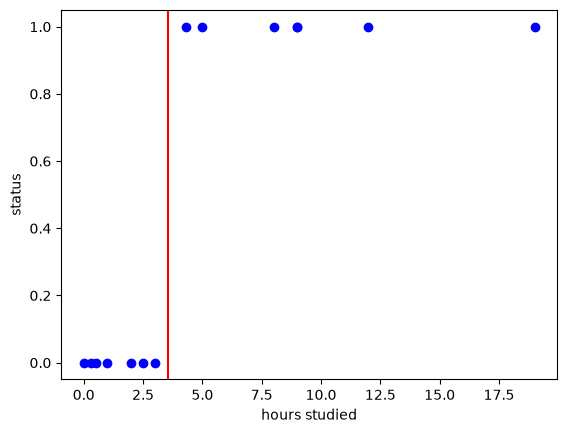

In [27]:
plt.scatter(x, y, label='Actual', color='blue')
bound = -b / w
plt.axvline(bound, color='red', label='Decision Boundary')
plt.xlabel("hours studied")
plt.ylabel("status")